In [7]:
import sys
import os
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils

In [8]:
import importlib
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py'>

In [9]:
api = wandb.Api()
username = 'julian-zim-uni-vie'

In [10]:
projects = {
	'll00': {
		'bom' : [
			'bom-ll00 26.01 09h30 0 2022-11-23_worm10',
			'bom-ll00 26.01 12h55 1 2022-11-23_worm11',
			'bom-ll00 26.01 16h25 7 2023-11-21_14-46_wt_worm4-2023-11-21',
			'bom-ll00 26.01 19h38 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
			'bom-ll00 26.01 23h15 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
			'bom-ll00 27.01 02h47 17 ZIM2165_Gcamp7b_worm1-2022-11-30',
			'bom-ll00 20.01 16h34 19 ZIM2165_Gcamp7b_worm1-2022_11_28',
			'bom-ll00 27.01 06h16 21 ZIM2165_Gcamp7b_worm2-2022-11-30',
		],
		'hgm' : [
			'hgm-ll00 28.01 17h48 0 2022-11-23_worm10',
			'hgm-ll00 29.01 06h08 1 2022-11-23_worm11',
			'hgm-ll00 29.01 18h42 2 2022-11-23_worm12',
			'hgm-ll00 30.01 07h14 3 2022-11-23_worm8',
			'hgm-ll00 30.01 19h53 4 2022-11-23_worm9',
			'hgm-ll00 31.01 08h21 5 2023-11-21_12-39_wt_worm1-2023-11-21',
			'hgm-ll00 31.01 20h33 6 2023-11-21_14-28_wt_worm3-2023-11-21',
			'hgm-ll00 01.02 09h28 7 2023-11-21_14-46_wt_worm4-2023-11-21',
			'hgm-ll00 01.02 21h01 8 2023-11-21_15-05_wt_worm5-2023-11-21',
			'hgm-ll00 02.02 10h33 9 2023-11-30_13-58_wt_worm3_FM-2023-11-30',
			'hgm-ll00 02.02 22h21 10 2023-11-30_14-31_wt_worm5_FM-2023-11-30',
			'hgm-ll00 03.02 10h07 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
			'hgm-ll00 03.02 21h17 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
			'hgm-ll00 04.02 08h35 13 2024-01-11_16-42_wt_FM_worm06-2024-01-11',

		],
		'bom_rs' : [
			'bom_rs-ll00 28.01 20h19 0 2022-11-23_worm10',
			'bom_rs-ll00 29.01 07h50 1 2022-11-23_worm11',
			'bom_rs-ll00 29.01 19h21 2 2022-11-23_worm12',
			'bom_rs-ll00 30.01 07h43 3 2022-11-23_worm8',
			'bom_rs-ll00 30.01 19h50 4 2022-11-23_worm9',
			'bom_rs-ll00 31.01 07h07 5 2023-11-21_12-39_wt_worm1-2023-11-21',
			'bom_rs-ll00 31.01 17h17 6 2023-11-21_14-28_wt_worm3-2023-11-21',
			'bom_rs-ll00 01.02 05h34 7 2023-11-21_14-46_wt_worm4-2023-11-21',
			'bom_rs-ll00 01.02 17h06 8 2023-11-21_15-05_wt_worm5-2023-11-21',
			'bom_rs-ll00 02.02 06h03 9 2023-11-30_13-58_wt_worm3_FM-2023-11-30',
			'bom_rs-ll00 02.02 17h35 10 2023-11-30_14-31_wt_worm5_FM-2023-11-30',
			'bom_rs-ll00 03.02 05h23 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
			'bom_rs-ll00 03.02 18h46 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
			'bom_rs-ll00 04.02 06h59 13 2024-01-11_16-42_wt_FM_worm06-2024-01-11',
		],
		'hgm_rs' : [
			'hgm_rs-ll00 28.01 20h13 0 2022-11-23_worm10',
			'hgm_rs-ll00 29.01 18h22 1 2022-11-23_worm11',
			'hgm_rs-ll00 30.01 14h47 2 2022-11-23_worm12',
			'hgm_rs-ll00 31.01 11h29 3 2022-11-23_worm8',
			'hgm_rs-ll00 01.02 10h06 4 2022-11-23_worm9',
			'hgm_rs-ll00 02.02 07h11 5 2023-11-21_12-39_wt_worm1-2023-11-21',
			'hgm_rs-ll00 03.02 04h33 6 2023-11-21_14-28_wt_worm3-2023-11-21',
			'hgm_rs-ll00 04.02 06h45 7 2023-11-21_14-46_wt_worm4-2023-11-21',
		],
	},
}

In [11]:
hyperparams = {
	ll: {
		model : {
			'means': {
				**(
					{'vb_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.endswith('rs') else {}
				),
				'wb_reg_lambda': {
					'linear': -1.,
					'geometric': -1.,
				},
				**(
					{'wm_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.startswith('hgm') else {}
				),
			},
			'datasets': {
				dataset: {
					'mpe_loss': {
						'all': np.empty(shape=()),
					},
					**(
						{'vb_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.endswith('rs') else {}
					),
					'wb_reg_lambda': {
						'all': np.empty(shape=()),
						'mean': {
							'linear': -1.,
							'geometric': -1.,
						},
					},
					**(
						{'wm_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.startswith('hgm') else {}
					),
				} for dataset in [' '.join(project.split(' ')[-2:]) for project in projects[ll][model]]
			},
		} for model in projects[ll].keys()
	} for ll in projects.keys()
}

In [12]:
percentile = 5

for ll in hyperparams.keys():
	for model in hyperparams[ll].keys():
		for dataset in hyperparams[ll][model]['datasets']:
			project = [name for name in projects[ll][model] if name.endswith(dataset)][0]

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')
			mpe_losses = np.array([run.summary.get('mpe_loss', float('inf')) for run in runs])

			print('sorting them...')
			mpe_losses, sorted_runs = zip(*sorted([(loss, run) for loss, run in zip(mpe_losses, runs) if loss != float('inf')]))

			print(f'processing mpe losses...')
			hyperparams[ll][model]['datasets'][dataset]['mpe_loss']['all'] = mpe_losses

			if model.endswith('rs'):
				print(f'processing vb_reg_lambdas...')
				vb_reg_lambdas = np.array([run.config['vb_reg_lambda'] for run in sorted_runs])
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['all'] = vb_reg_lambdas
				best_vb_reg_lambdas = vb_reg_lambdas[:int(percentile / 100 * len(vb_reg_lambdas))]
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['linear'] = np.mean(best_vb_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_vb_reg_lambdas)))

			print(f'processing wb_reg_lambdas...')
			wb_reg_lambdas = np.array([run.config['wb_reg_lambda'] for run in sorted_runs])
			hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['all'] = wb_reg_lambdas
			best_wb_reg_lambdas = wb_reg_lambdas[:int(percentile / 100 * len(wb_reg_lambdas))]
			hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['linear'] = np.mean(best_wb_reg_lambdas)
			hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wb_reg_lambdas)))

			if model.startswith('hgm'):
				print(f'processing wm_reg_lambdas...')
				wm_reg_lambdas = np.array([run.config['wm_reg_lambda'] for run in sorted_runs])
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['all'] = wm_reg_lambdas
				best_wm_reg_lambdas = wm_reg_lambdas[:int(percentile / 100 * len(wm_reg_lambdas))]
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['linear'] = np.mean(best_wm_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wm_reg_lambdas)))

		print('averaging across projects...')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			means_linear = np.array([
				hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean']['linear'] for dataset in hyperparams[ll][model]['datasets'].keys()
			])
			means_geometric = np.array([
				hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean']['geometric'] for dataset in hyperparams[ll][model]['datasets'].keys()
			])

			# use the min mean, except for wb_reg_lambda in the rs model, there use the max!
			if model.endswith('rs') and hyperparam == 'wb_reg_lambda':
				hyperparams[ll][model]['means'][hyperparam]['linear'] = np.max(means_linear).item()
				hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.max(np.log10(means_geometric))).item()
			else:
				hyperparams[ll][model]['means'][hyperparam]['linear'] = np.min(means_linear).item()
				hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.min(np.log10(means_geometric))).item()

			# hyperparams[ll][model]['means'][hyperparam]['linear'] = np.mean(means_linear).item()
			# hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.mean(np.log10(means_geometric))).item()

sorting them...
processing mpe losses...
processing vb_reg_lambdas...
processing wb_reg_lambdas...
processing wm_reg_lambdas...
averaging across projects...


In [13]:
for ll in hyperparams.keys():
	print(f'{ll}')
	for model in hyperparams[ll].keys():
		print(f'\t{model}')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			print(f'\t\t{hyperparam}')
			for mean_type in hyperparams[ll][model]['means'][hyperparam].keys():
				_mean = hyperparams[ll][model]['means'][hyperparam][mean_type]
				print(f'\t\t\t{mean_type}: \t{_mean}')

ll00
	bom
		wb_reg_lambda
			linear: 	0.016300814402742225
			geometric: 	0.016197936922070725
	hgm
		wb_reg_lambda
			linear: 	4.130339253786211e-06
			geometric: 	4.7160407208956316e-07
		wm_reg_lambda
			linear: 	7.829364780547882e-07
			geometric: 	5.327315973341022e-08
	bom_rs
		vb_reg_lambda
			linear: 	5.850639320040443e-06
			geometric: 	5.539321593935643e-07
		wb_reg_lambda
			linear: 	0.638178852462867
			geometric: 	0.48775914554328015
	hgm_rs
		vb_reg_lambda
			linear: 	0.00010956630943950008
			geometric: 	2.6370796405205155e-07
		wb_reg_lambda
			linear: 	0.45730948178547504
			geometric: 	0.2530333677361784
		wm_reg_lambda
			linear: 	7.765736401318542e-08
			geometric: 	2.004987039258706e-08


In [14]:
# with open('./hyperparams_old.pkl', 'rb') as file:
#     hyperparams = pickle.load(file)

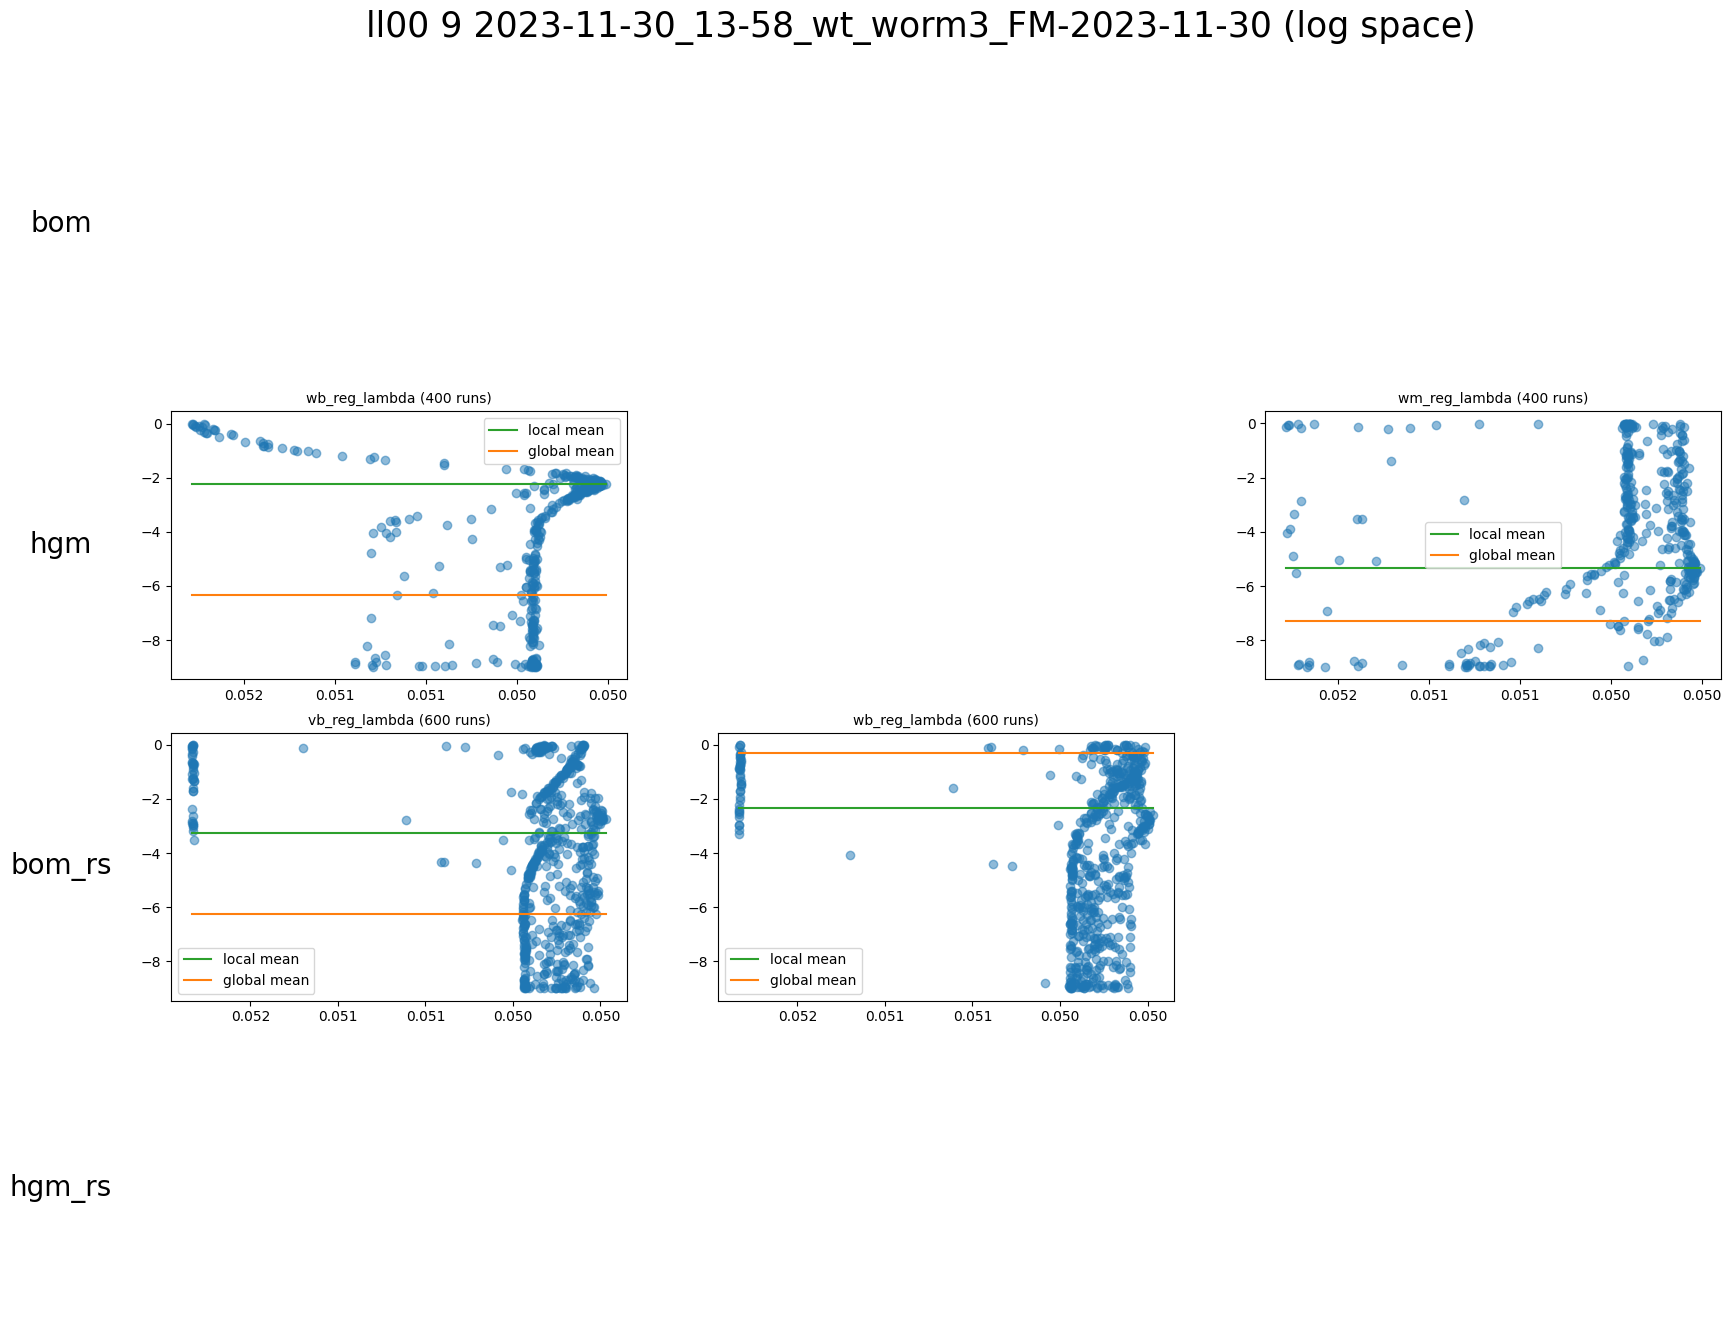

In [15]:
save = True
plot_utils.plot_hyperparams(hyperparams, None,
							ll='ll00', histograms=False, space='logarithmic',
							save_dirpath='../../out/plots/hyperparameters' if save else None)

In [16]:
with open('./hyperparams.pkl', 'wb') as file:
    pickle.dump(hyperparams, file)